# Week 5/8 Update - IDOT Ground Truth and Mapillary Image Matching

## About Ground Truth

**Illinois Department of Transportation**

https://www.gettingaroundillinois.com/

https://gis-idot.opendata.arcgis.com/datasets/IDOT::vertical-clearance/about


https://www.gettingaroundillinois.com/MapViewer/?config=OBSconfig.json



## 1. Setup and Configuration


In [1]:
import importlib.util
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import subprocess

    missing_packages = {
        "arcgis": "arcgis",
        "geopandas": "geopandas",
        "shapely": "shapely",
        "requests": "requests",
        "PIL": "pillow",
        "matplotlib": "matplotlib",
        "pandas": "pandas",
        "numpy": "numpy",
        "tqdm": "tqdm",
        "torch": "torch",
    }
    missing = [pip_name for module_name, pip_name in missing_packages.items() if importlib.util.find_spec(module_name) is None]
    if missing:
        print("Installing missing packages:", missing)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

    repair_packages = [
        "scipy>=1.13.0",
        "transformers>=4.45.0",
        "accelerate>=0.33.0",
        "safetensors>=0.4.5",
    ]
    print("Repairing Depth Anything dependencies:", repair_packages)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *repair_packages])

    print("If you already saw an AutoImageProcessor/scipy/numpy import error in this runtime, restart the Colab runtime once, then run all cells from the top.")


Repairing Depth Anything dependencies: ['scipy>=1.13.0', 'transformers>=4.45.0', 'accelerate>=0.33.0', 'safetensors>=0.4.5']
If you already saw an AutoImageProcessor/scipy/numpy import error in this runtime, restart the Colab runtime once, then run all cells from the top.


In [2]:
import math
import time
from getpass import getpass
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import requests
from IPython.display import Image, display

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

try:
    from arcgis.gis import GIS
except ImportError:
    GIS = None

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
IMAGE_DIR = PROJECT_ROOT / "mapillary_sequence_images"
DATA_DIR.mkdir(exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)

IDOT_ITEM_ID = "474c97d9a5074e8fbe09268f79ee39be"
MAX_GROUND_TRUTH_POINTS = 20
MATCH_POINTS_TO_QUERY = 5
MAPILLARY_SEARCH_RADIUS_M = 120
MAPILLARY_IMAGE_LIMIT = 30
SEQUENCE_SEARCH_RADIUS_M = 80
DEPTH_ANYTHING_MODEL_ID = "depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf"
ASSUMED_CAMERA_HORIZONTAL_FOV_DEG = 70

MAPILLARY_TOKEN = os.getenv("MAPILLARY_TOKEN", "").strip()
if not MAPILLARY_TOKEN and IN_COLAB:
    MAPILLARY_TOKEN = getpass("Paste Mapillary access token: ").strip()
    os.environ["MAPILLARY_TOKEN"] = MAPILLARY_TOKEN

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 140)

print("Running in Colab:", IN_COLAB)
print("ArcGIS package available:", GIS is not None)
print("Mapillary token available:", bool(MAPILLARY_TOKEN))


Paste Mapillary access token: ··········
Running in Colab: True
ArcGIS package available: True
Mapillary token available: True


## 2. Load IDOT Vertical Clearance Ground Truth



In [3]:
def load_idot_with_arcgis(item_id: str = IDOT_ITEM_ID) -> pd.DataFrame:
    """Load the IDOT Vertical Clearance layer through the ArcGIS Python API."""
    if GIS is None:
        raise ImportError(
            "The arcgis package is required for this notebook path. "
            "In Colab, rerun the setup cell so arcgis can be installed."
        )

    gis = GIS()
    item = gis.content.get(item_id)
    if item is None:
        raise RuntimeError(f"Could not find ArcGIS item: {item_id}")
    if not item.layers:
        raise RuntimeError(f"ArcGIS item has no layers: {item.title}")

    layer = item.layers[0]
    print("ArcGIS item title:", item.title)
    print("Layer name:", layer.properties.name)

    features_wgs = layer.query(
        where="1=1",
        out_fields="*",
        return_geometry=True,
        out_sr=4326,
        as_df=True,
    )

    return pd.DataFrame(features_wgs)


def extract_xy(shape: Any, axis: str) -> Optional[float]:
    """Extract x/y from ArcGIS SHAPE values that may be dict-like or geometry-like."""
    if isinstance(shape, dict):
        return shape.get(axis)
    if hasattr(shape, axis):
        return getattr(shape, axis)
    try:
        return shape[axis]
    except Exception:
        return None


def prepare_ground_truth(raw: pd.DataFrame) -> pd.DataFrame:
    """Clean IDOT records and derive numeric clearance values."""
    if raw.empty:
        raise RuntimeError("IDOT layer returned zero records.")

    gt = raw.copy()
    if "SHAPE" not in gt.columns:
        raise RuntimeError("IDOT layer did not include SHAPE geometry; cannot match to Mapillary without lon/lat.")

    gt["lon"] = gt["SHAPE"].apply(lambda geom: extract_xy(geom, "x"))
    gt["lat"] = gt["SHAPE"].apply(lambda geom: extract_xy(geom, "y"))
    gt["gt_clearance_in"] = pd.to_numeric(gt.get("FT_Height"), errors="coerce")
    gt["gt_clearance_ft"] = gt["gt_clearance_in"] / 12

    keep_columns = [
        "OBJECTID", "ObstructionNumber", "TYPE", "Location", "Description",
        "FT_Height", "TF_Height", "gt_clearance_in", "gt_clearance_ft", "lon", "lat",
    ]
    gt = gt[[col for col in keep_columns if col in gt.columns]].dropna(
        subset=["lon", "lat", "gt_clearance_in"]
    )

    return gt.reset_index(drop=True)

raw_gt = load_idot_with_arcgis()
gt = prepare_ground_truth(raw_gt)

print("Ground truth records:", gt.shape)
display(gt.head())


ArcGIS item title: Vertical Clearance
Layer name: Vertical Clearance
Ground truth records: (8826, 11)


,OBJECTID,ObstructionNumber,TYPE,Location,Description,FT_Height,TF_Height,gt_clearance_in,gt_clearance_ft,lon,lat
0,1,089X0001,O,BR20: FREEPORT @ GALENA AVE,"BR20: FREEPORT @ GALENA AVE, SIGN TRUSS, EB: 20-01, WB: 19-06",241,234,241,20.083333,-89.597293,42.280528
1,2,1019925,O,IL2: ROCKFORD @ CEDAR ST,"IL2: ROCKFORD @ CEDAR ST, UP RR, NB: 14-03, SB: 14-03",171,171,171,14.25,-89.097665,42.267052
2,3,101X0031,O,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-01",217,217,217,18.083333,-89.214512,42.280087
3,4,101X0032,O,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-6",222,222,222,18.5,-89.210363,42.280296
4,5,101X0033,O,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB: 18-10",226,226,226,18.833333,-89.205002,42.280519


## 3. Select Overhead / Sign-Truss Candidates


In [4]:
def select_overhead_candidates(gt: pd.DataFrame, max_points: int = MAX_GROUND_TRUTH_POINTS) -> pd.DataFrame:
    """Choose likely visible overhead clearance objects for the image matching pilot."""
    text_columns = [col for col in ["Description", "Location", "TYPE"] if col in gt.columns]
    search_text = gt[text_columns].fillna("").agg(" ".join, axis=1)

    overhead_mask = search_text.str.contains(
        r"SIGN\s*TRUSS|SIGN|TRUSS|OVERHEAD|GANTRY|STRUCTURE|BRIDGE",
        case=False,
        regex=True,
        na=False,
    )
    candidates = gt.loc[overhead_mask].copy()

    if candidates.empty:
        raise RuntimeError("No overhead/sign-truss candidates found in the IDOT layer.")

    return candidates.head(max_points).reset_index(drop=True)

sample_gt = select_overhead_candidates(gt)
print("Selected candidate count:", len(sample_gt))
display(sample_gt[["OBJECTID", "ObstructionNumber", "Location", "Description", "gt_clearance_ft", "lon", "lat"]].head(10))


Selected candidate count: 20


,OBJECTID,ObstructionNumber,Location,Description,gt_clearance_ft,lon,lat
0,1,089X0001,BR20: FREEPORT @ GALENA AVE,"BR20: FREEPORT @ GALENA AVE, SIGN TRUSS, EB: 20-01, WB: 19-06",20.083333,-89.597293,42.280528
1,3,101X0031,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-01",18.083333,-89.214512,42.280087
2,4,101X0032,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-6",18.5,-89.210363,42.280296
3,5,101X0033,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB: 18-10",18.833333,-89.205002,42.280519
4,9,101X0022,US20: W OF IL2,"US20: W OF IL2, SIGN TRUSS, EB: 18-0, EB: 18-0",18.0,-89.113180,42.219320
5,10,101X0022,US20 RAMP: W OF IL2,"US20 RAMP: W OF IL2, SIGN TRUSS, EB: 19-0",19.0,-89.113194,42.219175
6,13,101X0024,US20: E OF IL2,"US20: E OF IL2, SIGN TRUSS, WB: 16-3",16.25,-89.104783,42.219530
7,14,101X0024,US20 RAMP: E OF IL2,"US20 RAMP: E OF IL2, SIGN TRUSS, WB: 18-8",18.666667,-89.104741,42.219729
8,15,101X0025,US20 RAMP: W OF IL251,"US20 RAMP: W OF IL251, SIGN TRUSS, EB: 18-3",18.25,-89.076490,42.219383
9,16,101X0025,US20: E OF IL251,"US20: E OF IL251, SIGN TRUSS, EB: 17-9, EB: 17-9",17.75,-89.076494,42.219455


## 4. Match IDOT Ground Truth Points to Mapillary Images


In [5]:
def require_mapillary_token() -> str:
    """Return the Mapillary token or stop the notebook with a clear message."""
    token = os.getenv("MAPILLARY_TOKEN", "").strip() or MAPILLARY_TOKEN
    if not token:
        raise RuntimeError(
            "MAPILLARY_TOKEN is missing. In Colab, rerun the setup cell and paste your token, "
            "or run: os.environ['MAPILLARY_TOKEN'] = 'your_token_here'"
        )
    return token


def meters_to_deg_lat(meters: float) -> float:
    return meters / 111_320


def meters_to_deg_lon(meters: float, lat: float) -> float:
    return meters / (111_320 * max(math.cos(math.radians(lat)), 1e-6))


def haversine_m(lon1: float, lat1: float, lon2: float, lat2: float) -> float:
    radius_m = 6_371_000
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    d_phi = math.radians(lat2 - lat1)
    d_lambda = math.radians(lon2 - lon1)
    a = math.sin(d_phi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(d_lambda / 2) ** 2
    return 2 * radius_m * math.asin(math.sqrt(a))


def query_mapillary_images(lon: float, lat: float, token: str, radius_m: int = MAPILLARY_SEARCH_RADIUS_M, limit: int = MAPILLARY_IMAGE_LIMIT) -> List[Dict[str, Any]]:
    """Query Mapillary images near one longitude/latitude point."""
    dlat = meters_to_deg_lat(radius_m)
    dlon = meters_to_deg_lon(radius_m, lat)
    bbox = f"{lon - dlon},{lat - dlat},{lon + dlon},{lat + dlat}"

    params = {
        "access_token": token,
        "fields": "id,sequence,computed_geometry,thumb_1024_url,captured_at,compass_angle,is_pano",
        "bbox": bbox,
        "limit": limit,
    }

    response = requests.get("https://graph.mapillary.com/images", params=params, timeout=30)
    if response.status_code != 200:
        raise RuntimeError(f"Mapillary API error {response.status_code}: {response.text[:500]}")

    rows = []
    for image in response.json().get("data", []):
        coords = (image.get("computed_geometry") or {}).get("coordinates") or [None, None]
        image_lon, image_lat = coords[0], coords[1]
        if image_lon is None or image_lat is None:
            continue

        rows.append({
            "image_id": image.get("id"),
            "sequence": image.get("sequence"),
            "image_lon": image_lon,
            "image_lat": image_lat,
            "thumb_1024_url": image.get("thumb_1024_url"),
            "captured_at": image.get("captured_at"),
            "compass_angle": image.get("compass_angle"),
            "is_pano": image.get("is_pano"),
            "image_distance_m": haversine_m(lon, lat, image_lon, image_lat),
        })

    return sorted(rows, key=lambda row: row["image_distance_m"])


def build_mapillary_matches(sample: pd.DataFrame, points_to_query: int = MATCH_POINTS_TO_QUERY) -> pd.DataFrame:
    """Match selected IDOT points to their nearest Mapillary image."""
    token = require_mapillary_token()
    matches = []

    for _, gt_row in sample.head(points_to_query).iterrows():
        nearby_images = query_mapillary_images(gt_row["lon"], gt_row["lat"], token)
        if nearby_images:
            matches.append({**gt_row.to_dict(), **nearby_images[0], "has_mapillary": True})
        else:
            matches.append({**gt_row.to_dict(), "has_mapillary": False})
        time.sleep(0.2)

    match_df = pd.DataFrame(matches)
    if match_df.empty or not match_df.get("has_mapillary", pd.Series(dtype=bool)).any():
        raise RuntimeError(
            "No Mapillary images matched the selected IDOT points. "
            "Try increasing MAPILLARY_SEARCH_RADIUS_M or checking that the token is valid."
        )

    return match_df

match_df = build_mapillary_matches(sample_gt)
print(match_df["has_mapillary"].value_counts(dropna=False))
display(match_df[[
    "OBJECTID", "ObstructionNumber", "Location", "gt_clearance_ft",
    "has_mapillary", "image_id", "sequence", "image_distance_m", "captured_at",
]])


has_mapillary
True     4
False    1
Name: count, dtype: int64


,OBJECTID,ObstructionNumber,Location,gt_clearance_ft,has_mapillary,image_id,sequence,image_distance_m,captured_at
0,1,089X0001,BR20: FREEPORT @ GALENA AVE,20.083333,False,NaN,NaN,NaN,NaN
1,3,101X0031,US20: W OF STATE ST,18.083333,True,842149990032290,kdco8jujomymv4vcbnkxik,12.494489,1.440247e+12
2,4,101X0032,US20: W OF STATE ST,18.500000,True,3866482450140026,o78o310rzv1ora9so6nzke,24.624472,1.440247e+12
3,5,101X0033,US20: W OF STATE ST,18.833333,True,534536254383108,w031xzigq5i4og07aj024x,24.097984,1.440247e+12
4,9,101X0022,US20: W OF IL2,18.000000,True,802839940347830,5qr5a9dceaye55vpe31u4v,22.462870,1.440248e+12


## 5. Visually Inspect Matched Images


In [6]:
valid_matches = match_df.dropna(subset=["thumb_1024_url"]).copy()
if valid_matches.empty:
    raise RuntimeError("Mapillary returned matches but no thumbnail URLs. Check requested fields or token permissions.")

for _, row in valid_matches.iterrows():
    print("=" * 90)
    print("OBJECTID:", row["OBJECTID"])
    print("Location:", row["Location"])
    print("Description:", row["Description"])
    print("Ground truth clearance ft:", round(row["gt_clearance_ft"], 2))
    print("Image distance m:", round(row["image_distance_m"], 2))
    print("Image ID:", row["image_id"])
    print("Sequence:", row.get("sequence"))
    display(Image(url=row["thumb_1024_url"], width=700))


OBJECTID: 3
Location: US20: W OF STATE ST
Description: US20: W OF STATE ST, SIGN TRUSS, EB: 18-01
Ground truth clearance ft: 18.08
Image distance m: 12.49
Image ID: 842149990032290
Sequence: kdco8jujomymv4vcbnkxik


OBJECTID: 4
Location: US20: W OF STATE ST
Description: US20: W OF STATE ST, SIGN TRUSS, EB: 18-6
Ground truth clearance ft: 18.5
Image distance m: 24.62
Image ID: 3866482450140026
Sequence: o78o310rzv1ora9so6nzke


OBJECTID: 5
Location: US20: W OF STATE ST
Description: US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB: 18-10
Ground truth clearance ft: 18.83
Image distance m: 24.1
Image ID: 534536254383108
Sequence: w031xzigq5i4og07aj024x


OBJECTID: 9
Location: US20: W OF IL2
Description: US20: W OF IL2, SIGN TRUSS, EB: 18-0, EB: 18-0
Ground truth clearance ft: 18.0
Image distance m: 22.46
Image ID: 802839940347830
Sequence: 5qr5a9dceaye55vpe31u4v


In [7]:
TOKEN = os.environ["MAPILLARY_TOKEN"]

image_id = "328584465265744"

gt_lat = 42.219320
gt_lon = -89.113180


def haversine_m(lon1, lat1, lon2, lat2):
    R = 6371000  # Earth radius in meters

    lon1, lat1, lon2, lat2 = map(
        math.radians,
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    )

    c = 2 * math.asin(math.sqrt(a))
    return R * c


url = f"https://graph.mapillary.com/{image_id}"

params = {
    "access_token": TOKEN,
    "fields": "id,computed_geometry,captured_at,compass_angle,thumb_1024_url,sequence"
}

r = requests.get(url, params=params, timeout=30)

print("Status:", r.status_code)
print(r.text[:500])

meta = r.json()

geom = meta.get("computed_geometry", {})
coords = geom.get("coordinates", [None, None])

image_lon = coords[0]
image_lat = coords[1]

distance_m = haversine_m(gt_lon, gt_lat, image_lon, image_lat)
distance_ft = distance_m * 3.28084

result = pd.DataFrame([{
    "image_id": image_id,
    "gt_lat": gt_lat,
    "gt_lon": gt_lon,
    "image_lat": image_lat,
    "image_lon": image_lon,
    "distance_m": distance_m,
    "distance_ft": distance_ft,
    "captured_at": meta.get("captured_at"),
    "compass_angle": meta.get("compass_angle"),
    "sequence": meta.get("sequence"),
    "thumb_1024_url": meta.get("thumb_1024_url")
}])

display(result)

print(f"Distance to ground truth: {distance_m:.2f} meters")
print(f"Distance to ground truth: {distance_ft:.2f} feet")

Status: 200
{"id":"328584465265744","computed_geometry":{"type":"Point","coordinates":[-89.113536108816,42.219291423033]},"captured_at":1440247642851,"compass_angle":90.308677312321,"thumb_1024_url":"https:\/\/scontent-ord5-3.xx.fbcdn.net\/m1\/v\/t6\/An8Xff-APf3lVhpnB04XyWX8ABOuxcr0YHiJIMWCkTzhoYbw9kBkO932MX_75GKd8WsQnGBfuHsB8oA6AUUJnpWmBSvA2vKrnQueR5XyLeqF6C61Xne0ux0RPifSVDjKQjyn3pVYVzF6SHrWG0mbUw?stp=s1024x768&edm=ALXxkZ8EAAAA&_nc_gid=sv5XEV1a8h_9Lbg_S_HhNw&_nc_oc=Adq-SP8cQFDQfa_FR0OIRTZCuWK0-yMlIBxeB3uu4


,image_id,gt_lat,gt_lon,image_lat,image_lon,distance_m,distance_ft,captured_at,compass_angle,sequence,thumb_1024_url
0,328584465265744,42.21932,-89.11318,42.219291,-89.113536,29.496699,96.773951,1440247642851,90.308677,5qr5a9dceaye55vpe31u4v,https://scontent-ord5-3.xx.fbcdn.net/m1/v/t6/An8Xff-APf3lVhpnB04XyWX8ABOuxcr0YHiJIMWCkTzhoYbw9kBkO932MX_75GKd8WsQnGBfuHsB8oA6AUUJnpWmBSv...


Distance to ground truth: 29.50 meters
Distance to ground truth: 96.77 feet


In [8]:
from IPython.display import Image, display
display(Image(url=meta["thumb_1024_url"], width=700))

## 6. Choose Pilot Image


Pilot case
OBJECTID: 9
Location: US20: W OF IL2
Description: US20: W OF IL2, SIGN TRUSS, EB: 18-0, EB: 18-0
Ground truth clearance ft: 18.0
Image distance m: 29.52
Image ID: 328584465265744
Local image path: pilot_images/pilot_328584465265744.jpg


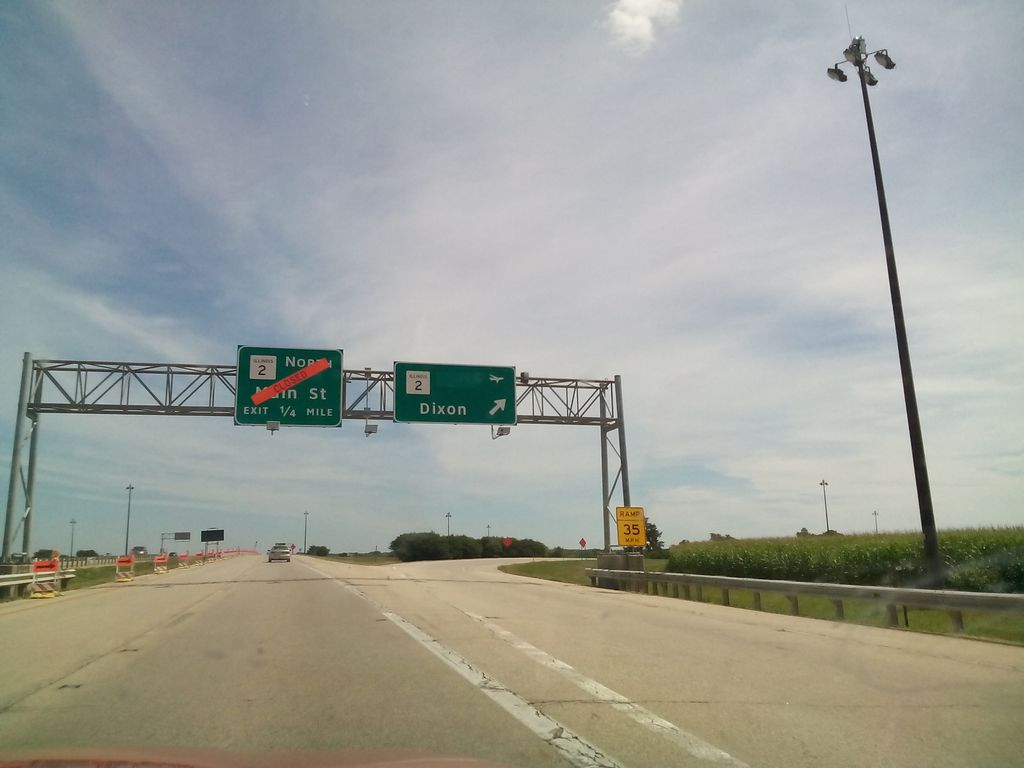

In [26]:
IMAGE_DIR = Path("pilot_images")
IMAGE_DIR.mkdir(exist_ok=True)

def download_image(url, output_path):
    r = requests.get(url, timeout=30)
    r.raise_for_status()
    output_path.write_bytes(r.content)
    return output_path

def haversine_m(lon1, lat1, lon2, lat2):
    R = 6371000
    lon1, lat1, lon2, lat2 = map(math.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = math.sin(dlat / 2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2)**2
    return 2 * R * math.asin(math.sqrt(a))

# Use manually selected image from meta
gt_row = gt[gt["OBJECTID"] == 9].iloc[0]

image_id = str(meta["id"])
image_lon, image_lat = meta["computed_geometry"]["coordinates"]
thumb_url = meta["thumb_1024_url"]

pilot = gt_row.copy()
pilot["image_id"] = image_id
pilot["thumb_1024_url"] = thumb_url
pilot["image_lon"] = image_lon
pilot["image_lat"] = image_lat
pilot["image_distance_m"] = haversine_m(
    gt_row["lon"], gt_row["lat"],
    image_lon, image_lat
)
pilot["captured_at"] = meta.get("captured_at")
pilot["compass_angle"] = meta.get("compass_angle")
pilot["sequence"] = meta.get("sequence")

pilot_image_path = download_image(
    thumb_url,
    IMAGE_DIR / f"pilot_{image_id}.jpg"
)

print("Pilot case")
print("OBJECTID:", pilot["OBJECTID"])
print("Location:", pilot["Location"])
print("Description:", pilot["Description"])
print("Ground truth clearance ft:", round(pilot["gt_clearance_ft"], 2))
print("Image distance m:", round(pilot["image_distance_m"], 2))
print("Image ID:", pilot["image_id"])
print("Local image path:", pilot_image_path)

display(Image(filename=str(pilot_image_path), width=700))

In [32]:
# Use Mapillary camera parameters instead of assumed FOV
# cam_params = meta.get("camera_parameters")
# camera_type = meta.get("camera_type")

# if cam_params is not None and len(cam_params) > 0 and camera_type == "perspective":
#     focal_norm = float(cam_params[0])
#     fx = focal_norm * w
#     fy = focal_norm * w
#     focal_source = "mapillary_camera_parameters"
# else:
#     fallback_fov_deg = 70
#     fx = w / (2 * np.tan(np.deg2rad(fallback_fov_deg / 2)))
#     fy = fx
#     focal_source = f"fallback_assumed_fov_{fallback_fov_deg}"

# print("fx:", fx)
# print("fy:", fy)
# print("focal source:", focal_source)

fx: 918.666725392681
fy: 918.666725392681
focal source: mapillary_camera_parameters


In [33]:
print(h, w)

768 1024


## 7. Run Depth Anything

Depth Anything model: depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf
Device: cpu


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Depth map shape: (768, 1024)
Depth saved to: pilot_images/depth_metric_328584465265744.npy
Depth range, meters: 6.882 to 72.575


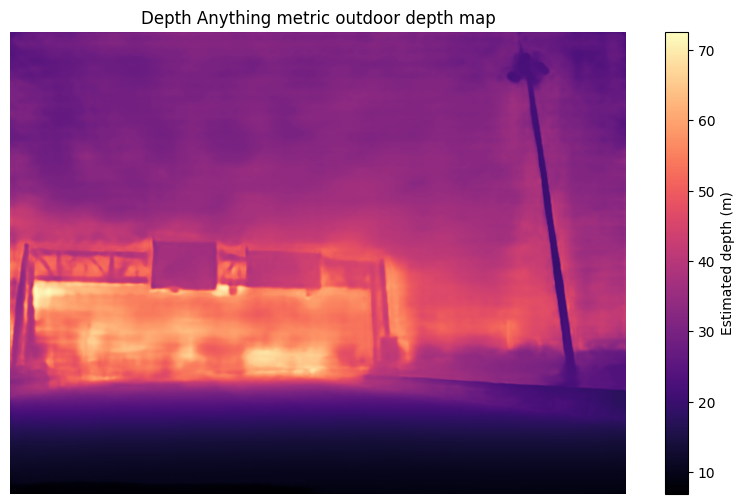

In [27]:
import subprocess

if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "--upgrade",
        "scipy>=1.13.0", "transformers>=4.45.0", "accelerate>=0.33.0", "safetensors>=0.4.5"
    ])

import torch
import torch.nn.functional as F
from PIL import Image as PILImage

try:
    from transformers import AutoImageProcessor, AutoModelForDepthEstimation
except Exception as exc:
    raise RuntimeError(
        "Could not import Depth Anything dependencies. In Colab, run the setup cell, "
        "then Runtime > Restart session, then Run all. Original error: " + repr(exc)
    )


def run_depth_anything_metric(image_path: Path, model_id: str = DEPTH_ANYTHING_MODEL_ID) -> np.ndarray:
    """Run Depth Anything metric outdoor model and return a depth map in image pixels."""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Depth Anything model:", model_id)
    print("Device:", device)

    image = PILImage.open(image_path).convert("RGB")
    image_processor = AutoImageProcessor.from_pretrained(model_id)
    model = AutoModelForDepthEstimation.from_pretrained(model_id).to(device)
    model.eval()

    inputs = image_processor(images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        predicted_depth = outputs.predicted_depth

    prediction = F.interpolate(
        predicted_depth.unsqueeze(1),
        size=image.size[::-1],
        mode="bicubic",
        align_corners=False,
    ).squeeze()

    depth_m = prediction.detach().cpu().numpy().astype(float)
    return depth_m


depth_m = run_depth_anything_metric(pilot_image_path)
depth_path = IMAGE_DIR / f"depth_metric_{pilot['image_id']}.npy"
np.save(depth_path, depth_m)

print("Depth map shape:", depth_m.shape)
print("Depth saved to:", depth_path)
print("Depth range, meters:", round(float(np.nanmin(depth_m)), 3), "to", round(float(np.nanmax(depth_m)), 3))

if plt is not None:
    plt.figure(figsize=(10, 6))
    plt.imshow(depth_m, cmap="magma")
    plt.colorbar(label="Estimated depth (m)")
    plt.axis("off")
    plt.title("Depth Anything metric outdoor depth map")
    plt.show()



## 8. Manual Object and Road Regions


,region,box,pixel_count,depth_mean_m,depth_median_m,depth_std_m
0,object_box,"(160, 350, 620, 420)",32200,43.385204,43.565168,4.84182
1,road_box,"(180, 580, 400, 590)",2200,40.015036,39.720921,3.04779


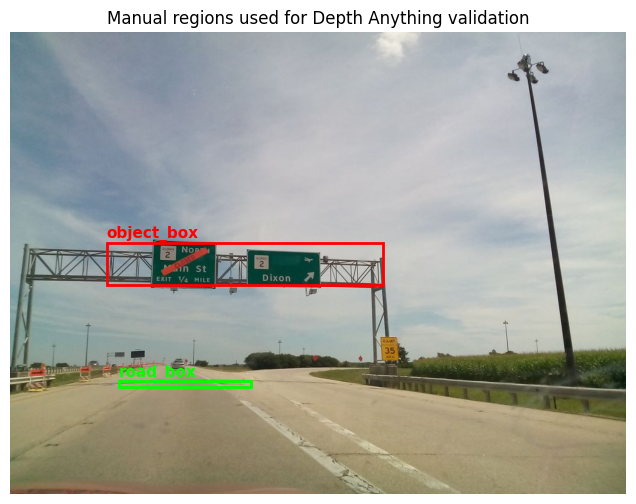

In [20]:

manual_regions = {
    # Format: (x1, y1, x2, y2). Update these after looking at the selected pilot image.
    "object_box": (160, 350, 620, 420),
    "road_box": (180, 580, 400, 590),
}
rx1, ry1, rx2, ry2 = 180, 580, 400, 590
bx1, by1, bx2, by2 = 160, 350, 620, 420

def crop_depth(depth: np.ndarray, box: tuple) -> np.ndarray:
    """Return depth values inside a pixel bounding box."""
    h, w = depth.shape[:2]
    x1, y1, x2, y2 = [int(v) for v in box]
    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)
    return depth[y1:y2, x1:x2]


def summarize_depth_regions(depth: np.ndarray, regions: dict) -> pd.DataFrame:
    """Summarize Depth Anything estimates inside each manual region."""
    rows = []
    for region_name, box in regions.items():
        values = crop_depth(depth, box)
        rows.append({
            "region": region_name,
            "box": box,
            "pixel_count": int(values.size),
            "depth_mean_m": float(np.nanmean(values)),
            "depth_median_m": float(np.nanmedian(values)),
            "depth_std_m": float(np.nanstd(values)),
        })
    return pd.DataFrame(rows)


depth_region_summary = summarize_depth_regions(depth_m, manual_regions)
display(depth_region_summary)

if plt is not None:
    import matplotlib.patches as patches

    image = PILImage.open(pilot_image_path).convert("RGB")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(image)
    ax.axis("off")

    colors = {"object_box": "red", "road_box": "lime"}
    for name, (x1, y1, x2, y2) in manual_regions.items():
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=colors[name], linewidth=2)
        ax.add_patch(rect)
        ax.text(x1, max(y1 - 8, 0), name, color=colors[name], fontsize=11, weight="bold")

    plt.title("Manual regions used for Depth Anything validation")
    plt.show()



## 9. Depth Anything Validation Against IDOT Ground Truth


In [34]:

def box_bottom_center(box: tuple) -> tuple:
    """Use the bottom-center pixel as the overhead object's lowest visible point."""
    x1, y1, x2, y2 = box
    return int((x1 + x2) / 2), int(y2)


def box_center(box: tuple) -> tuple:
    """Use the box center as the road reference point."""
    x1, y1, x2, y2 = box
    return int((x1 + x2) / 2), int((y1 + y2) / 2)


def median_depth_around_point(depth: np.ndarray, x: int, y: int, radius: int = 8) -> float:
    """Use a small local window so the estimate is less sensitive to one noisy pixel."""
    h, w = depth.shape[:2]
    x1, x2 = max(0, x - radius), min(w, x + radius + 1)
    y1, y2 = max(0, y - radius), min(h, y + radius + 1)
    return float(np.nanmedian(depth[y1:y2, x1:x2]))


def focal_pixels_from_horizontal_fov(width_px: int, horizontal_fov_deg: float) -> float:
    """Approximate focal length in pixels from an assumed horizontal field of view."""
    return width_px / (2 * math.tan(math.radians(horizontal_fov_deg) / 2))


def camera_vertical_coordinate_m(y_px: int, depth_m_value: float, image_height: int, focal_y_px: float) -> float:
    """Convert image y plus depth into approximate camera vertical coordinate."""
    cy = image_height / 2
    return (y_px - cy) * depth_m_value / focal_y_px


def estimate_clearance_from_depth(depth: np.ndarray, regions: dict, horizontal_fov_deg: float = ASSUMED_CAMERA_HORIZONTAL_FOV_DEG) -> dict:
    """Estimate clearance using Depth Anything depth and a rough camera model."""
    image_height, image_width = depth.shape[:2]
    focal_px = focal_pixels_from_horizontal_fov(image_width, horizontal_fov_deg)

    object_x, object_y = box_bottom_center(regions["object_box"])
    road_x, road_y = box_center(regions["road_box"])

    object_depth_m = median_depth_around_point(depth, object_x, object_y)
    road_depth_m = median_depth_around_point(depth, road_x, road_y)

    object_vertical_m = camera_vertical_coordinate_m(object_y, object_depth_m, image_height, focal_px)
    road_vertical_m = camera_vertical_coordinate_m(road_y, road_depth_m, image_height, focal_px)
    estimated_clearance_m = abs(road_vertical_m - object_vertical_m)

    return {
        "object_pixel": (object_x, object_y),
        "road_pixel": (road_x, road_y),
        "object_depth_m": object_depth_m,
        "road_depth_m": road_depth_m,
        "assumed_horizontal_fov_deg": horizontal_fov_deg,
        "estimated_clearance_m": estimated_clearance_m,
        "estimated_clearance_ft": estimated_clearance_m / 0.3048,
    }


clearance_estimate = estimate_clearance_from_depth(depth_m, manual_regions)
gt_clearance_ft = float(pilot["gt_clearance_ft"])
gt_clearance_m = gt_clearance_ft * 0.3048

validation_result = pd.DataFrame([{
    "OBJECTID": pilot["OBJECTID"],
    "Location": pilot["Location"],
    "Mapillary image ID": pilot["image_id"],
    "GT clearance ft": gt_clearance_ft,
    "GT clearance m": gt_clearance_m,
    "Depth Anything estimate ft": clearance_estimate["estimated_clearance_ft"],
    "Depth Anything estimate m": clearance_estimate["estimated_clearance_m"],
    "Absolute error ft": abs(clearance_estimate["estimated_clearance_ft"] - gt_clearance_ft),
    "Absolute error m": abs(clearance_estimate["estimated_clearance_m"] - gt_clearance_m),
    "Object depth m": clearance_estimate["object_depth_m"],
    "Road depth m": clearance_estimate["road_depth_m"],
    "Object pixel": clearance_estimate["object_pixel"],
    "Road pixel": clearance_estimate["road_pixel"],
}])

display(validation_result)


,OBJECTID,Location,Mapillary image ID,GT clearance ft,GT clearance m,Depth Anything estimate ft,Depth Anything estimate m,Absolute error ft,Absolute error m,Object depth m,Road depth m,Object pixel,Road pixel
0,9,US20: W OF IL2,328584465265744,18.0,5.4864,28.483901,8.681893,10.483901,3.195493,43.948929,39.455044,"(390, 420)","(290, 585)"



## 10. Final Depth Anything Pilot Summary


In [29]:

final_depth_anything_summary = pd.DataFrame([{
    "OBJECTID": pilot["OBJECTID"],
    "ObstructionNumber": pilot["ObstructionNumber"],
    "Location": pilot["Location"],
    "Description": pilot["Description"],
    "Mapillary image ID": pilot["image_id"],
    "Image distance m": round(float(pilot["image_distance_m"]), 2),
    "GT clearance ft": round(gt_clearance_ft, 2),
    "Depth Anything estimate ft": round(float(clearance_estimate["estimated_clearance_ft"]), 2),
    "Absolute error ft": round(float(abs(clearance_estimate["estimated_clearance_ft"] - gt_clearance_ft)), 2),
    "Pilot image path": str(pilot_image_path),
    "Depth map path": str(depth_path)
}])

display(final_depth_anything_summary)


,OBJECTID,ObstructionNumber,Location,Description,Mapillary image ID,Image distance m,GT clearance ft,Depth Anything estimate ft,Absolute error ft,Pilot image path,Depth map path
0,9,101X0022,US20: W OF IL2,"US20: W OF IL2, SIGN TRUSS, EB: 18-0, EB: 18-0",328584465265744,29.52,18.0,28.48,10.48,pilot_images/pilot_328584465265744.jpg,pilot_images/depth_metric_328584465265744.npy


In [31]:
import os
import requests
import pandas as pd

TOKEN = os.environ["MAPILLARY_TOKEN"]
image_id = str(pilot["image_id"])

url = f"https://graph.mapillary.com/{image_id}"

params = {
    "access_token": TOKEN,
    "fields": ",".join([
        "id",
        "camera_parameters",
        "camera_type",
        "width",
        "height",
        "make",
        "model",
        "computed_geometry",
        "computed_compass_angle",
        "compass_angle",
        "captured_at",
        "thumb_1024_url"
    ])
}

r = requests.get(url, params=params, timeout=30)
print("Status:", r.status_code)
print(r.text[:1000])

cam_meta = r.json()
display(pd.DataFrame([cam_meta]))

Status: 200
{"id":"328584465265744","camera_parameters":[0.89713547401629,3.1171132267581e-6,8.4681595956026e-5],"camera_type":"perspective","width":2560,"height":1920,"make":"BLU                            ","model":"STUDIO 5.5                     ","computed_geometry":{"type":"Point","coordinates":[-89.113536108816,42.219291423033]},"computed_compass_angle":106.47706789051,"compass_angle":90.308677312321,"captured_at":1440247642851,"thumb_1024_url":"https:\/\/scontent-ord5-3.xx.fbcdn.net\/m1\/v\/t6\/An8Xff-APf3lVhpnB04XyWX8ABOuxcr0YHiJIMWCkTzhoYbw9kBkO932MX_75GKd8WsQnGBfuHsB8oA6AUUJnpWmBSvA2vKrnQueR5XyLeqF6C61Xne0ux0RPifSVDjKQjyn3pVYVzF6SHrWG0mbUw?stp=s1024x768&edm=ALXxkZ8EAAAA&_nc_gid=QIAGulbhyHybJx3uYZTgYA&_nc_oc=Adq-SP8cQFDQfa_FR0OIRTZCuWK0-yMlIBxeB3uu4RFod3p5PX5jJH4Yj7rij-ch1xg&ccb=10-5&oh=00_Af6B2H4Om_TQfdnjHNci2eqDIcnviB9a_gek1QqGHTS8HQ&oe=6A2C448F&_nc_sid=201bca"}


,id,camera_parameters,camera_type,width,height,make,model,computed_geometry,computed_compass_angle,compass_angle,captured_at,thumb_1024_url
0,328584465265744,"[0.89713547401629, 3.1171132267581e-06, 8.4681595956026e-05]",perspective,2560,1920,BLU,STUDIO 5.5,"{'type': 'Point', 'coordinates': [-89.113536108816, 42.219291423033]}",106.477068,90.308677,1440247642851,https://scontent-ord5-3.xx.fbcdn.net/m1/v/t6/An8Xff-APf3lVhpnB04XyWX8ABOuxcr0YHiJIMWCkTzhoYbw9kBkO932MX_75GKd8WsQnGBfuHsB8oA6AUUJnpWmBSv...
